<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/11_Vulnerability_Software_Supply_Chain_Attacks/HybridQNN_SmartContractVuln_Durgut2025.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Hybrid quantum-classical deep neural network for smart-contract vulnerability detection: Durgut et al. (2025) step by step

**Paper.** Sinan Durgut, Ecir Ugur Kucuksille, Mahmut Tokmak, *Hybrid Quantum-Classical Deep Neural Networks Based Smart Contract Vulnerability Detection*, Applied Sciences 15(7), 4037, 2025. DOI [10.3390/app15074037](https://doi.org/10.3390/app15074037).

**What this notebook does.** The paper reads the EVM **opcodes** of an Ethereum smart contract, turns them into **TF-IDF bigram** features, squeezes them with one dense layer into 2 (or 4) numbers, feeds those numbers as rotation angles into a tiny **PennyLane** circuit (angle embedding + CNOT entangling layer, Pauli-Z read-out), and puts a one-neuron sigmoid on top. The model says "vulnerable" or "not vulnerable" for one vulnerability type at a time (access control, reentrancy, arithmetic, ...). The paper reports accuracy between 78.2 % and 96.4 % and says the 2-qubit and 4-qubit hybrids beat a classical DNN. This notebook

1. downloads a **public substitute dataset**: about 100 000 real Ethereum contracts with deployed bytecode and the output of the **Slither** static analyser (Hugging Face `mwritescode/slither-audited-smart-contracts`). The paper's Slither rows (access control, reentrancy, unchecked low-level calls) have a direct counterpart there,
2. disassembles the bytecode to opcode text, builds the paper's TF-IDF bigram features (fitted on the training split only),
3. trains the **2-qubit and 4-qubit HQCDNN** and two classical DNNs on identical inputs, plus Random Forest, RBF-SVM and logistic regression,
4. re-checks the paper's side claims: 4 qubits are 2-3 times slower than 2, the Wilcoxon test over 10-fold cross-validation, and "bigrams beat unigrams",
5. prints the paper's numbers next to the notebook's with a verdict per claim.

**How to run.** Google Colab, CPU runtime, *Runtime -> Run all*. Everything is downloaded inside the notebook (a few Parquet columns streamed from Hugging Face, no GPU). With `FAST_MODE = True` the whole notebook runs in a few minutes; `FAST_MODE = False` uses larger samples, three seeds and 10-fold cross-validation (the runtime is printed at the end).

**What you get at the end.** A working hybrid model you can read line by line, an honest side-by-side with the paper (the time-manipulation and denial-of-service rows cannot be checked with this public data, and the notebook says so), and a critical reading of the paper's claims.

## The paper in one page

- **Problem.** Find security flaws in Ethereum smart contracts (immutable once deployed). Seven vulnerability types: access control, arithmetic, front-running, reentrancy, time manipulation, denial of service, unchecked low-level calls.
- **Data.** SmartBugs *Wild*: 47 587 real contracts, of which 45 877 compile with `solcx` (Solidity >= 0.4.11). Nine analysis tools labelled them; only (tool, vulnerability) pairs with more than 1 000 hits are used (Table 2: Mythril, Osiris, Oyente, Securify, Slither, Smartcheck) and combinations of tools that flag the same contract (Table 3). 3 665 contracts that no tool flagged are the "non-vulnerable" class.
- **Binary task per (vulnerability, tool).** Vulnerable (flagged) versus non-vulnerable; balanced to at most 3 665 per class; **80 % / 20 %** train / test.
- **Features.** Opcodes extracted from the compiled contract, **TF-IDF with 2-grams** (default settings; 1-gram was worse, 3-gram too expensive).
- **Model (HQCDNN).** Dense layer (to as many units as qubits, ReLU) -> PennyLane `default.qubit` with 2 (or 4) wires: **AngleEmbedding** (rotations), **BasicEntangler** (CNOT), Pauli-Z expectation on each qubit -> one dense neuron with sigmoid. Classical back-propagation trains everything. Python 3.12, Keras 2.14, TensorFlow 2.14, PennyLane 0.40.
- **Baseline.** A classical DNN on the same data (architecture not described).
- **Claims.** Accuracy 78.2-96.4 %, F1 80.2-96.6 % over all tables (Tables 4-10); both quantum models beat the DNN "in nearly all cases"; the 4-qubit model is slightly better (small gains) but needs 2-3 times the time; a Wilcoxon signed-rank test over 10-fold CV (arithmetic, Osiris+Oyente+Smartcheck, 2 qubits vs DNN) gives p = 0.0020.
- **Slither rows of the tables** (accuracy / F1; 2 qubits | 4 qubits | DNN), which this notebook targets:

| Vulnerability (Slither) | Table | 2 qubits | 4 qubits | DNN |
|---|---|---|---|---|
| Access control | 4 | 0.924 / 0.926 | 0.920 / 0.920 | 0.854 / 0.857 |
| Reentrancy | 5 | 0.918 / 0.944 | 0.915 / 0.915 | 0.870 / 0.869 |
| Time manipulation | 7 | 0.908 / 0.911 | 0.910 / 0.915 | 0.878 / 0.882 |
| Denial of service | 9 | 0.930 / 0.932 | 0.937 / 0.938 | 0.883 / 0.888 |
| Unchecked low calls | 10 | 0.928 / 0.954 | 0.915 / 0.914 | 0.887 / 0.885 |

## What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Dataset | SmartBugs Wild (45 877 contracts, labels from 9 tools run on the Solidity source) | **Substitute:** Hugging Face `mwritescode/slither-audited-smart-contracts` (about 100 000 verified Ethereum contracts, deployed bytecode, **Slither** detector output). Only the Slither rows of the paper can be compared. The SmartBugs Wild labels of the other tools are not downloadable in a few lines |
| Vulnerability types | 7 | **3 checkable:** access control (`arbitrary-send`, `tx-origin`, `suicidal`, `controlled-delegatecall`, ... as in the dataset's `label_mappings.json`), reentrancy (`reentrancy-eth`, `reentrancy-no-eth`), unchecked low calls (`unused-return`, `unchecked-lowlevel`, `unchecked-transfer`). **Time manipulation and denial of service cannot be checked**: this dataset has no `timestamp` or `calls-loop` detector output. Arithmetic is a different Slither rule here (`divide-before-multiply`) and is not used |
| Non-vulnerable class | contracts that no tool flagged | contracts with no Slither detector from a relevant class (the dataset's `safe`) |
| Vulnerable class | flagged by the tool for that type (a contract may carry other flags too) | same: flagged for the type, other flags allowed |
| Opcode source | opcodes of the **compiled source** (`solcx`) | opcodes of the **deployed runtime bytecode** (own disassembler; PUSH data skipped, metadata cut). `# CHOICE:` mnemonics only, no operands |
| Duplicates | not mentioned | identical bytecode (clones) is kept once, so clones cannot sit in both train and test |
| Sample size | up to 3 665 per class (balanced) | `FAST_MODE`: 400 per class; full: 1 500 per class (balanced) |
| Split | 80 % / 20 % | stratified 80 % / 20 %, 15 % of the training part used as validation to pick the best epoch (`# CHOICE:`) |
| TF-IDF | 2-grams, default scikit-learn parameters | `TfidfVectorizer(ngram_range=(2, 2))`, tokens = opcode mnemonics, `lowercase=False`, **fitted on the training split only** |
| Quantum layer | AngleEmbedding (R_X) + BasicEntangler (CNOT) + Pauli-Z, 2 or 4 qubits, `default.qubit` | same. `# CHOICE:` one entangling layer (the paper's Eq. 9 shows one) |
| Framework | Keras 2.14 + `qml.qnn.KerasLayer` | **PyTorch + `qml.qnn.TorchLayer`.** `KerasLayer` no longer exists in current PennyLane (Keras 3). Same maths, same circuit |
| Optimiser, learning rate, batch size, epochs, initialisation | not reported | `# CHOICE:` Adam, learning rate in the config cell, batch 32, epochs in the config cell, best epoch by validation loss; first dense layer bias starts at 0.1 so that its 2-4 ReLU units do not die at the start |
| Loss / output | sigmoid, binary classification | sigmoid via `BCEWithLogitsLoss` (numerically the same) |
| Classical DNN | "a classical DNN", not described | two variants (`# CHOICE:`): **DNN-matched** (same as the HQCDNN with the quantum layer replaced by a dense `n x n` layer with tanh, i.e. same width and output range) and **DNN-wide** (64-32 ReLU) |
| Other baselines | none in the main tables (literature numbers only in Table 11) | RandomForest, SVC(rbf), logistic regression on the same TF-IDF inputs |
| Repeats | one run per cell, 10-fold CV only for the Wilcoxon test | `FAST_MODE`: 1 seed; full: seeds 42-44 (mean +/- std) |
| Statistical test | Wilcoxon, arithmetic task, 2 qubits vs DNN, 10-fold CV | same test on the **reentrancy** task (the arithmetic task is not available) |
| Hardware | none (simulator) | exact simulator (`default.qubit`), no hardware |

In [1]:
# Installs, pinned to the versions this notebook was tested with. Colab already ships numpy, pandas, scikit-learn,
# matplotlib, seaborn, scipy, torch and pyarrow. A session restart may be required if an import below fails.
import importlib.util, subprocess, sys
IN_COLAB = "google.colab" in sys.modules
need = []
if IN_COLAB or importlib.util.find_spec("pennylane") is None:
    need += ["pennylane==0.45.1"]
for pkg in ["huggingface_hub", "pyarrow", "torch", "seaborn"]:
    if importlib.util.find_spec(pkg) is None:
        need.append(pkg)                  # CPU build of torch is enough
if need:
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", *need], check=False)
    print("installed:", need, "(restart the runtime if an import below fails)")
else:
    print("nothing to install")

nothing to install


### Configuration

Every tunable constant is here. `FAST_MODE = True` is the class demo (small samples, few epochs, one seed). `FAST_MODE = False` is the full run (larger samples, three seeds, 10-fold cross-validation).

In [2]:
# ---------------- configuration: every tunable constant lives here ----------------
SEED = 42
FAST_MODE = False           # True: a few minutes; False: full budgets (runtime is printed at the end)
IBM_TOKEN = ""              # unused: nothing here runs on quantum hardware
DATA_DIR = "smartcontract_data"
HF_REPO = "mwritescode/slither-audited-smart-contracts"      # public substitute dataset (CHOICE)
SHARDS = [0] if FAST_MODE else [0, 1]                         # raw shards of ~15 000 contracts each

TASKS = ["access-control", "reentrancy", "unchecked-calls"]   # vulnerability types with a Slither counterpart in the paper
N_PER_CLASS = 400 if FAST_MODE else 1500                      # vulnerable and non-vulnerable contracts per task (balanced; the paper: up to 3665)
TEST_SIZE = 0.20                                              # paper: 80 % / 20 %
VAL_FRAC = 0.15                                               # part of the training split used to pick the best epoch (CHOICE)

QUBITS = [2, 4]                                               # the paper's two quantum layers
N_ENTANGLER_LAYERS = 1                                        # CHOICE: one BasicEntangler layer
EPOCHS = 10 if FAST_MODE else 20                              # CHOICE: the paper does not report epochs
BATCH = 32                                                    # CHOICE
LR = 0.01                                                     # CHOICE: Adam
SEEDS = [42] if FAST_MODE else [42, 43, 44]

CV_TASK = "reentrancy"                                        # task for the Wilcoxon test (the paper used arithmetic)
CV_FOLDS = 5 if FAST_MODE else 10                             # the paper: 10-fold
CV_EPOCHS = 8 if FAST_MODE else 15
ABLATION_TASK = "reentrancy"                                  # unigram vs bigram check

In [3]:
import os, json, time, copy, random, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import torch, torch.nn as nn
import pennylane as qml
import sklearn, scipy
from scipy.stats import wilcoxon
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
warnings.filterwarnings("ignore")
T_NOTEBOOK = time.time()

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
set_seed(SEED)
rng = np.random.default_rng(SEED)
torch.set_num_threads(max(1, min(4, os.cpu_count() or 1)))
os.makedirs(DATA_DIR, exist_ok=True)
sns.set_theme(style="whitegrid")
print("numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__, "| torch", torch.__version__, "| pennylane", qml.__version__)

numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1 | torch 2.14.1+cpu | pennylane 0.45.1


## 1. Data: Ethereum contracts labelled by Slither

The paper's SmartBugs Wild labels come from nine tools run on the Solidity source of 47 000 contracts. We use a public dataset that did the same with **Slither alone** and also kept the **deployed bytecode** (M. Rossini, *Slither Audited Smart Contracts*, 2022). Each of its raw Parquet shards holds 15 000 contracts; we read only the `contracts`, `bytecode` and `results` columns straight from Hugging Face (the `source_code` column is most of the file size).

Slither's detector names are mapped to vulnerability classes by the dataset's own `label_mappings.json`. For each task we follow the paper's protocol as closely as the data allows:

- **vulnerable** = Slither flagged the contract for that type (it may carry other flags as well, as in the paper),
- **non-vulnerable** = Slither raised no relevant detector at all,
- both classes balanced to the same number of contracts.

Identical bytecode (token clones, proxies) is kept once; otherwise copies of one contract could land in both the training and the test split and inflate every score.

In [4]:
import pyarrow.parquet as pq
from huggingface_hub import HfFileSystem, hf_hub_download

mapping_path = hf_hub_download(HF_REPO, "data/label_mappings.json", repo_type="dataset", local_dir=DATA_DIR)
LABEL_MAP = json.load(open(mapping_path))

def slither_classes(results_json):
    # classes flagged for one contract (empty tuple = nothing relevant flagged = non-vulnerable)
    r = json.loads(results_json)
    if not r.get("results"):
        return ()
    return tuple(sorted({LABEL_MAP[d["check"]] for d in r["results"]["detectors"]} - {"ignore"}))

def read_shard(i):
    cols = ["contracts", "bytecode", "results"]
    try:                                                 # stream only three columns
        with HfFileSystem().open(f"datasets/{HF_REPO}/data/raw/contracts{i}.parquet", "rb") as f:
            return pq.ParquetFile(f).read(columns=cols).to_pandas()
    except Exception as e:
        print("streaming failed (", type(e).__name__, "), downloading the whole shard instead")
        p = hf_hub_download(HF_REPO, f"data/raw/contracts{i}.parquet", repo_type="dataset", local_dir=DATA_DIR)
        return pq.read_table(p, columns=cols).to_pandas()

pool_path = os.path.join(DATA_DIR, f"pool_{'-'.join(map(str, SHARDS))}_{N_PER_CLASS}_{'-'.join(TASKS)}.pkl")
if os.path.exists(pool_path):
    pool = pd.read_pickle(pool_path)
    print("loaded cached pool:", pool_path)
else:
    parts = []
    for i in SHARDS:
        t0 = time.time(); df = read_shard(i)
        df = df[df.bytecode.str.len() > 200].copy()                  # drop contracts whose bytecode could not be fetched
        df["cls"] = df.results.map(slither_classes)
        parts.append(df.drop(columns="results"))
        print(f"shard {i}: {len(df)} contracts, {time.time()-t0:.1f} s")
    full = pd.concat(parts, ignore_index=True).drop_duplicates("bytecode")   # clones: keep one (CHOICE)
    print("unique contracts:", len(full))
    chosen = {}
    safe = full[full.cls.map(len) == 0]
    for t in TASKS:
        vuln = full[full.cls.map(lambda c: t in c)]
        n = min(N_PER_CLASS, len(vuln), len(safe))
        for r in vuln.sample(n, random_state=SEED).itertuples():
            chosen[r.Index] = r
        print(f"{t}: vulnerable available {len(vuln)}, used {n}")
    # one shared pool of non-vulnerable contracts; each task draws its own balanced subset from it later
    for r in safe.sample(min(len(safe), N_PER_CLASS * len(TASKS)), random_state=SEED).itertuples():
        chosen[r.Index] = r
    pool = full.loc[list(chosen)].reset_index(drop=True)
    pool.to_pickle(pool_path)
    print("saved pool:", pool_path)

print("pool:", len(pool), "contracts")
summary = pd.DataFrame({"vulnerable": {t: int(pool.cls.map(lambda c, t=t: t in c).sum()) for t in TASKS},
                        "non-vulnerable in pool": int((pool.cls.map(len) == 0).sum())})
display(summary)

shard 0: 14824 contracts, 6.0 s


shard 1: 14845 contracts, 5.3 s


unique contracts: 28771


access-control: vulnerable available 4626, used 1500


reentrancy: vulnerable available 8675, used 1500


unchecked-calls: vulnerable available 11684, used 1500


saved pool: smartcontract_data\pool_0-1_1500_access-control-reentrancy-unchecked-calls.pkl
pool: 8602 contracts


,vulnerable,non-vulnerable in pool
access-control,2075,4500
reentrancy,2894,4500
unchecked-calls,3222,4500


## 2. From bytecode to opcode text

The paper uses the opcodes of the compiled contract. We disassemble the deployed **runtime bytecode**: every byte is an opcode, except the bytes right after `PUSH1`..`PUSH32`, which are data and must be skipped; the compiler's CBOR metadata at the end is cut off. Each contract becomes one long "sentence" of opcode names such as `PUSH1 MSTORE CALLVALUE DUP1 ISZERO ...`.

`# CHOICE:` the paper does not say whether operands are kept. We keep mnemonics only (so `PUSH1 0x80` is `PUSH1`); operands would turn every constant into a different word.

In [5]:
NAMES = {0x00: "STOP", 0x01: "ADD", 0x02: "MUL", 0x03: "SUB", 0x04: "DIV", 0x05: "SDIV", 0x06: "MOD", 0x07: "SMOD", 0x08: "ADDMOD",
         0x09: "MULMOD", 0x0a: "EXP", 0x0b: "SIGNEXTEND", 0x10: "LT", 0x11: "GT", 0x12: "SLT", 0x13: "SGT", 0x14: "EQ", 0x15: "ISZERO",
         0x16: "AND", 0x17: "OR", 0x18: "XOR", 0x19: "NOT", 0x1a: "BYTE", 0x1b: "SHL", 0x1c: "SHR", 0x1d: "SAR", 0x20: "SHA3",
         0x30: "ADDRESS", 0x31: "BALANCE", 0x32: "ORIGIN", 0x33: "CALLER", 0x34: "CALLVALUE", 0x35: "CALLDATALOAD", 0x36: "CALLDATASIZE",
         0x37: "CALLDATACOPY", 0x38: "CODESIZE", 0x39: "CODECOPY", 0x3a: "GASPRICE", 0x3b: "EXTCODESIZE", 0x3c: "EXTCODECOPY",
         0x3d: "RETURNDATASIZE", 0x3e: "RETURNDATACOPY", 0x3f: "EXTCODEHASH", 0x40: "BLOCKHASH", 0x41: "COINBASE", 0x42: "TIMESTAMP",
         0x43: "NUMBER", 0x44: "DIFFICULTY", 0x45: "GASLIMIT", 0x46: "CHAINID", 0x47: "SELFBALANCE", 0x48: "BASEFEE", 0x50: "POP",
         0x51: "MLOAD", 0x52: "MSTORE", 0x53: "MSTORE8", 0x54: "SLOAD", 0x55: "SSTORE", 0x56: "JUMP", 0x57: "JUMPI", 0x58: "PC",
         0x59: "MSIZE", 0x5a: "GAS", 0x5b: "JUMPDEST", 0xf0: "CREATE", 0xf1: "CALL", 0xf2: "CALLCODE", 0xf3: "RETURN",
         0xf4: "DELEGATECALL", 0xf5: "CREATE2", 0xfa: "STATICCALL", 0xfd: "REVERT", 0xfe: "INVALID", 0xff: "SELFDESTRUCT"}
for k in range(32): NAMES[0x60 + k] = f"PUSH{k+1}"
for k in range(16): NAMES[0x80 + k] = f"DUP{k+1}"; NAMES[0x90 + k] = f"SWAP{k+1}"
for k in range(5): NAMES[0xa0 + k] = f"LOG{k}"

def opcode_text(hexcode):
    # runtime bytecode (hex string) -> "PUSH1 PUSH1 MSTORE ..." (PUSH data skipped, trailing metadata removed)
    b = bytes.fromhex(hexcode[2:] if hexcode.startswith("0x") else hexcode)
    if len(b) > 2:
        meta = int.from_bytes(b[-2:], "big")                    # solc appends CBOR metadata; its length is in the last 2 bytes
        if 0 < meta < len(b) - 2:
            b = b[:-(meta + 2)]
    out, i, n = [], 0, len(b)
    while i < n:
        op = b[i]; out.append(NAMES.get(op, "INVALID"))
        i += 1 + (op - 0x5F if 0x60 <= op <= 0x7F else 0)
    return " ".join(out)

t0 = time.time()
pool["ops"] = [opcode_text(h) for h in pool.bytecode]
pool = pool.drop(columns="bytecode")                              # free memory
print(f"disassembled {len(pool)} contracts in {time.time()-t0:.0f} s; median length {int(pool.ops.str.count(' ').median())+1} opcodes")
ex = pool.iloc[0]
print("example contract", ex.contracts, "| flagged classes:", ex.cls)
print("first 25 opcodes:", ex.ops.split()[:25])

disassembled 8602 contracts in 19 s; median length 3251 opcodes
example contract 3a354bfea2b3a00b1130446e80650c5462f702bf | flagged classes: ('access-control', 'arithmetic')
first 25 opcodes: ['PUSH1', 'PUSH1', 'MSTORE', 'PUSH1', 'CALLDATASIZE', 'LT', 'PUSH2', 'JUMPI', 'PUSH1', 'CALLDATALOAD', 'PUSH29', 'SWAP1', 'DIV', 'PUSH4', 'AND', 'DUP1', 'PUSH4', 'EQ', 'PUSH2', 'JUMPI', 'DUP1', 'PUSH4', 'EQ', 'PUSH2', 'JUMPI']


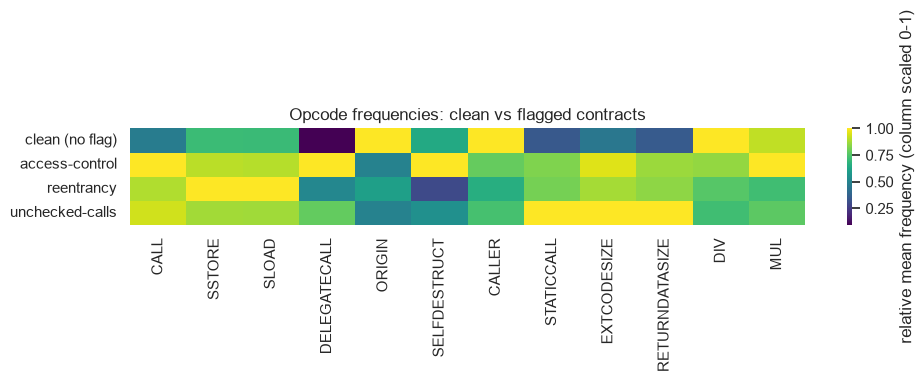

In [6]:
# Which opcodes are more frequent in vulnerable than in clean contracts? (relative frequency of selected opcodes)
show = ["CALL", "SSTORE", "SLOAD", "DELEGATECALL", "ORIGIN", "SELFDESTRUCT", "CALLER", "STATICCALL", "EXTCODESIZE", "RETURNDATASIZE", "DIV", "MUL"]
def rel_freq(texts):
    return np.mean([[t.split().count(o) / (t.count(" ") + 1) for o in show] for t in texts], axis=0)
clean = pool[pool.cls.map(len) == 0].ops.head(300)
rows = {"clean (no flag)": rel_freq(clean)}
for t in TASKS:
    rows[t] = rel_freq(pool[pool.cls.map(lambda c, t=t: t in c)].ops.head(300))
H = pd.DataFrame(rows, index=show).T
plt.figure(figsize=(10, 3))
sns.heatmap(H / (H.max(0) + 1e-12), cmap="viridis", cbar_kws={"label": "relative mean frequency (column scaled 0-1)"})
plt.title("Opcode frequencies: clean vs flagged contracts"); plt.tight_layout(); plt.show()

## 3. TF-IDF on opcode bigrams, per vulnerability type

For one task we draw `N_PER_CLASS` vulnerable and the same number of non-vulnerable contracts, split 80 % / 20 % (stratified), and then **fit** the `TfidfVectorizer` on the training part only: `ngram_range=(2, 2)` (word pairs such as `CALL SSTORE`, the pattern behind reentrancy), otherwise scikit-learn defaults, as in the paper. The test part is only transformed. A further 15 % of the training part is held out as validation set for picking the best epoch. Nothing from the test split is used for any fitting.

In [7]:
def make_split(task, seed, ngram=(2, 2)):
    """Balanced vulnerable / non-vulnerable sample, stratified 80/20 split, TF-IDF fitted on the training part only."""
    vuln = pool[pool.cls.map(lambda c: task in c)]
    safe = pool[pool.cls.map(len) == 0]
    n = min(N_PER_CLASS, len(vuln), len(safe))
    d = pd.concat([vuln.sample(n, random_state=seed), safe.sample(n, random_state=seed)])
    texts, y = d.ops.tolist(), np.r_[np.ones(n), np.zeros(n)].astype("float32")
    tr_t, te_t, ytr, yte = train_test_split(texts, y, test_size=TEST_SIZE, stratify=y, random_state=seed)
    vec = TfidfVectorizer(ngram_range=ngram, token_pattern=r"\S+", lowercase=False)   # paper: default parameters, 2-grams
    Xtr = vec.fit_transform(tr_t).astype("float32").toarray()                          # fitted on the training split only
    Xte = vec.transform(te_t).astype("float32").toarray()
    return Xtr, Xte, ytr, yte, vec

Xtr, Xte, ytr, yte, vec = make_split(TASKS[1], SEED)
print(TASKS[1], "| train", Xtr.shape, "| test", Xte.shape, "| bigram vocabulary:", len(vec.vocabulary_))
top = pd.Series(np.asarray(Xtr[ytr == 1].mean(0) - Xtr[ytr == 0].mean(0)).ravel(), index=vec.get_feature_names_out()).sort_values()
print("bigrams most typical of the vulnerable class:", list(top.index[-6:][::-1]))
print("bigrams most typical of the clean class     :", list(top.index[:6]))

reentrancy | train (2400, 6906) | test (600, 6906) | bigram vocabulary: 6906
bigrams most typical of the vulnerable class: ['PUSH1 SHL', 'JUMP JUMPDEST', 'PUSH1 PUSH1', 'PUSH2 JUMP', 'SHL SUB', 'PUSH1 DUP3']
bigrams most typical of the clean class     : ['PUSH20 AND', 'PUSH1 ADD', 'ADD SWAP1', 'DUP2 MSTORE', 'ADD SWAP2', 'MLOAD DUP1']


## 4. The hybrid model (HQCDNN)

Layer by layer, exactly as in Section 4 of the paper:

1. **Dense** (TF-IDF features -> `n` units, ReLU): reduces thousands of features to as many numbers as qubits.
2. **Quantum node** on PennyLane's `default.qubit` simulator: `AngleEmbedding` (the `n` numbers become R_X rotation angles), `BasicEntanglerLayers` (a trainable R_X on every qubit followed by a ring of CNOTs; for 2 qubits one CNOT), and the **Pauli-Z expectation value** of each qubit as output (`n` numbers in [-1, 1]).
3. **Dense(1) + sigmoid**: the probability "vulnerable".

PennyLane differentiates the simulated circuit exactly (`diff_method="backprop"`), so the whole stack is trained with ordinary back-propagation and Adam. Below the circuit is drawn, and the classical **DNN-matched** twin (quantum node replaced by a dense `n x n` layer with tanh) and the wider **DNN-wide** are defined next to it.

In [8]:
def make_qlayer(n_qubits):
    dev = qml.device("default.qubit", wires=n_qubits)
    @qml.qnode(dev, interface="torch", diff_method="backprop")
    def circuit(inputs, weights):
        qml.AngleEmbedding(inputs, wires=range(n_qubits), rotation="X")          # classical numbers -> rotation angles
        qml.BasicEntanglerLayers(weights, wires=range(n_qubits), rotation=qml.RX)  # CNOT entangling layer (+ trainable rotations)
        return [qml.expval(qml.PauliZ(i)) for i in range(n_qubits)]
    return qml.qnn.TorchLayer(circuit, {"weights": (N_ENTANGLER_LAYERS, n_qubits)}), circuit

print(qml.draw(make_qlayer(2)[1])(np.array([0.3, 1.1]), np.array([[0.5, -0.2]])))
print(qml.draw(make_qlayer(4)[1])(np.array([0.3, 1.1, 0.7, 0.2]), np.ones((N_ENTANGLER_LAYERS, 4)) * 0.4))

def build_model(kind, n_in, n):
    if kind == "hqcdnn":
        m = nn.Sequential(nn.Linear(n_in, n), nn.ReLU(), make_qlayer(n)[0], nn.Linear(n, 1))
    elif kind == "dnn_matched":
        m = nn.Sequential(nn.Linear(n_in, n), nn.ReLU(), nn.Linear(n, n), nn.Tanh(), nn.Linear(n, 1))
    elif kind == "dnn_wide":
        m = nn.Sequential(nn.Linear(n_in, 64), nn.ReLU(), nn.Linear(64, 32), nn.ReLU(), nn.Linear(32, 1))
    else:
        raise ValueError(kind)
    # CHOICE: the first dense layer (ReLU, only 2-4 units) can "die" (all units negative for every input -> constant output, 50 % accuracy).
    # A small positive bias at the start avoids it. The paper does not say how it initialised the weights.
    nn.init.constant_(m[0].bias, 0.1)
    return m

for kind, n in [("hqcdnn", 2), ("dnn_matched", 2), ("dnn_wide", 2)]:
    m = build_model(kind, 1000, n)
    print(f"{kind:12s} parameters (1000 input features): {sum(p.numel() for p in m.parameters()):,}")

0: ─╭AngleEmbedding(M0)─╭BasicEntanglerLayers(M1)─┤  <Z>
1: ─╰AngleEmbedding(M0)─╰BasicEntanglerLayers(M1)─┤  <Z>

M0 = 
[0.3 1.1]
M1 = 
[[ 0.5 -0.2]]


0: ─╭AngleEmbedding(M0)─╭BasicEntanglerLayers(M1)─┤  <Z>
1: ─├AngleEmbedding(M0)─├BasicEntanglerLayers(M1)─┤  <Z>
2: ─├AngleEmbedding(M0)─├BasicEntanglerLayers(M1)─┤  <Z>
3: ─╰AngleEmbedding(M0)─╰BasicEntanglerLayers(M1)─┤  <Z>

M0 = 
[0.3 1.1 0.7 0.2]
M1 = 
[[0.4 0.4 0.4 0.4]]
hqcdnn       parameters (1000 input features): 2,007
dnn_matched  parameters (1000 input features): 2,011
dnn_wide     parameters (1000 input features): 66,177


In [9]:
def metrics(y, p):
    return dict(acc=accuracy_score(y, p) * 100, prec=precision_score(y, p, zero_division=0) * 100,
                rec=recall_score(y, p, zero_division=0) * 100, f1=f1_score(y, p, zero_division=0) * 100)

def _train_once(kind, n, Xtr, ytr, Xte, seed, epochs, history):
    set_seed(seed)
    Xa, Xv, ya, yv = train_test_split(Xtr, ytr, test_size=VAL_FRAC, stratify=ytr, random_state=seed)
    Xa, Xv, ya, yv, Xt = map(torch.tensor, (Xa, Xv, ya[:, None], yv[:, None], Xte))
    model = build_model(kind, Xa.shape[1], n)
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    loss_fn = nn.BCEWithLogitsLoss()
    best, best_state, hist = (1e9, None, 0.0), None, []
    t0 = time.time()
    for ep in range(epochs):
        model.train(); perm = torch.randperm(len(Xa))
        for i in range(0, len(Xa), BATCH):
            idx = perm[i:i + BATCH]
            opt.zero_grad(); loss = loss_fn(model(Xa[idx]), ya[idx]); loss.backward(); opt.step()
        model.eval()
        with torch.no_grad():
            zv = model(Xv); vl = loss_fn(zv, yv).item()
            tl = loss_fn(model(Xa), ya).item()
        hist.append((tl, vl))
        if vl < best[0]:
            best, best_state = (vl, ep, float(((zv > 0).float() == yv).float().mean())), copy.deepcopy(model.state_dict())
    train_s = time.time() - t0
    model.load_state_dict(best_state); model.eval()
    t1 = time.time()
    with torch.no_grad():
        pred = (model(Xt)[:, 0] > 0).numpy().astype(int)         # sigmoid(z) > 0.5  <=>  z > 0
    return pred, train_s, time.time() - t1, best, hist

def train_eval(kind, n, Xtr, ytr, Xte, yte, seed, epochs=None, history=False):
    """Train with Adam on BCE (sigmoid output), keep the epoch with the best validation loss, evaluate once on the test split.
    CHOICE: if the best epoch is still a constant predictor on the validation split (validation accuracy < 60 %, a 'dead ReLU' start
    with only 2-4 hidden units), the run is restarted with another seed, at most twice; the number of restarts is reported."""
    epochs = epochs or EPOCHS
    restarts, total_s = 0, 0.0
    for attempt in range(3):
        pred, train_s, pred_s, best, hist = _train_once(kind, n, Xtr, ytr, Xte, seed + 1000 * attempt, epochs, history)
        total_s += train_s
        if best[2] >= 0.60:
            break
        restarts += 1
    out = dict(**metrics(yte, pred), train_s=train_s, pred_s=pred_s, best_epoch=best[1] + 1, restarts=restarts, pred=pred)
    if history: out["hist"] = hist
    return out
# quick smoke test on one task (2-qubit model)
t0 = time.time(); r = train_eval("hqcdnn", 2, Xtr, ytr, Xte, yte, SEED, history=True)
print(f"2-qubit HQCDNN on {TASKS[1]}: acc {r['acc']:.1f} F1 {r['f1']:.1f} (best epoch {r['best_epoch']}, {time.time()-t0:.0f} s)")

2-qubit HQCDNN on reentrancy: acc 94.3 F1 94.5 (best epoch 10, 36 s)


## 5. Classical baselines on the same TF-IDF inputs

The paper compares only against a classical DNN (above). As a sanity check we also fit a **Random Forest**, an **RBF-SVM** and **logistic regression** on exactly the same TF-IDF matrices. These need no GPU and run in seconds. If a Random Forest matches the quantum hybrid, the quantum layer is not what makes the numbers good.

In [10]:
def baselines(Xtr, ytr, Xte, yte, seed):
    out = {}
    for name, mk in [("RandomForest", lambda: RandomForestClassifier(n_estimators=300, random_state=seed, n_jobs=2)),
                     ("SVC (rbf)", lambda: SVC(kernel="rbf", C=1.0, random_state=seed)),
                     ("LogReg", lambda: LogisticRegression(max_iter=2000, random_state=seed))]:
        t0 = time.time(); m = mk().fit(Xtr, ytr); p = m.predict(Xte)
        out[name] = dict(**metrics(yte, p), train_s=time.time() - t0, pred=p)
    return out
print("defined baselines")

defined baselines


## 6. Run every task, model and seed

For each vulnerability type (the paper's Slither rows) and each seed the code draws the balanced sample, fits TF-IDF on the training split, and trains: the 2-qubit and 4-qubit HQCDNN, DNN-matched and DNN-wide (both with 2 and 4 hidden units where it applies), and the three scikit-learn baselines. The progress line shows accuracy and time per model.

In [11]:
records, keep = [], {}
t_all = time.time()
for task in TASKS:
    for seed in SEEDS:
        Xtr_, Xte_, ytr_, yte_, vec_ = make_split(task, seed)
        runs = {}
        for n in QUBITS:
            runs[f"HQCDNN {n}q"] = train_eval("hqcdnn", n, Xtr_, ytr_, Xte_, yte_, seed, history=True)
            runs[f"DNN-matched {n}"] = train_eval("dnn_matched", n, Xtr_, ytr_, Xte_, yte_, seed, history=True)
        runs["DNN-wide"] = train_eval("dnn_wide", 2, Xtr_, ytr_, Xte_, yte_, seed, history=True)
        runs.update(baselines(Xtr_, ytr_, Xte_, yte_, seed))
        for name, r in runs.items():
            records.append(dict(task=task, seed=seed, model=name, **{k: r[k] for k in ["acc", "prec", "rec", "f1", "train_s"]}, restarts=r.get("restarts", 0)))
            if seed == SEEDS[0]:
                keep[(task, name)] = dict(pred=r["pred"], y=yte_, hist=r.get("hist"))
        print(f"{task:16s} seed {seed} | features {Xtr_.shape[1]:5d} | " +
              " | ".join(f"{k} {runs[k]['acc']:.1f}" for k in ["HQCDNN 2q", "HQCDNN 4q", "DNN-matched 2", "DNN-wide", "RandomForest"]) +
              f" | {time.time()-t_all:.0f} s elapsed")
R = pd.DataFrame(records)
print(f"done in {(time.time()-t_all)/60:.1f} min | runs that needed a restart after a dead-ReLU start: {int((R.restarts > 0).sum())} of {len(R)}")

access-control   seed 42 | features  6802 | HQCDNN 2q 92.7 | HQCDNN 4q 92.3 | DNN-matched 2 93.0 | DNN-wide 92.7 | RandomForest 93.2 | 173 s elapsed


access-control   seed 43 | features  6482 | HQCDNN 2q 91.8 | HQCDNN 4q 92.3 | DNN-matched 2 91.5 | DNN-wide 92.3 | RandomForest 92.8 | 357 s elapsed


access-control   seed 44 | features  5929 | HQCDNN 2q 92.7 | HQCDNN 4q 92.5 | DNN-matched 2 93.0 | DNN-wide 93.3 | RandomForest 95.2 | 555 s elapsed


reentrancy       seed 42 | features  6906 | HQCDNN 2q 94.3 | HQCDNN 4q 94.3 | DNN-matched 2 95.0 | DNN-wide 94.7 | RandomForest 95.5 | 735 s elapsed


reentrancy       seed 43 | features  6658 | HQCDNN 2q 91.3 | HQCDNN 4q 90.8 | DNN-matched 2 90.8 | DNN-wide 89.8 | RandomForest 94.0 | 921 s elapsed


reentrancy       seed 44 | features  6190 | HQCDNN 2q 94.2 | HQCDNN 4q 94.7 | DNN-matched 2 94.0 | DNN-wide 94.3 | RandomForest 95.5 | 1101 s elapsed


unchecked-calls  seed 42 | features  6844 | HQCDNN 2q 90.5 | HQCDNN 4q 90.5 | DNN-matched 2 91.7 | DNN-wide 90.5 | RandomForest 91.7 | 1291 s elapsed


unchecked-calls  seed 43 | features  6467 | HQCDNN 2q 91.3 | HQCDNN 4q 91.0 | DNN-matched 2 90.5 | DNN-wide 91.8 | RandomForest 93.8 | 1425 s elapsed


unchecked-calls  seed 44 | features  6075 | HQCDNN 2q 92.3 | HQCDNN 4q 92.7 | DNN-matched 2 92.3 | DNN-wide 92.0 | RandomForest 94.2 | 1564 s elapsed
done in 26.1 min | runs that needed a restart after a dead-ReLU start: 0 of 72


## 7. Results: tables and figures

Metrics follow the paper: accuracy, precision, recall and F1 with "vulnerable" as the positive class, on the 20 % test split. With several seeds the tables show mean +/- standard deviation.

In [12]:
def ms(s): return f"{s.mean():.1f}" + (f" +/- {s.std(ddof=0):.1f}" if len(s) > 1 else "")
order = ["HQCDNN 2q", "HQCDNN 4q", "DNN-matched 2", "DNN-matched 4", "DNN-wide", "RandomForest", "SVC (rbf)", "LogReg"]
for task in TASKS:
    sub = R[R.task == task]
    tab = pd.DataFrame({m: {k: ms(sub[sub.model == m][k]) for k in ["acc", "prec", "rec", "f1", "train_s"]} for m in order}).T
    tab.columns = ["Accuracy %", "Precision %", "Recall %", "F1 %", "train time s"]
    print(f"\n=== {task} (n = {len(SEEDS)} seed(s)) ==="); display(tab)


=== access-control (n = 3 seed(s)) ===


,Accuracy %,Precision %,Recall %,F1 %,train time s
HQCDNN 2q,92.4 +/- 0.4,91.8 +/- 0.8,93.1 +/- 0.2,92.4 +/- 0.3,29.7 +/- 2.0
HQCDNN 4q,92.4 +/- 0.1,92.2 +/- 1.4,92.7 +/- 1.7,92.4 +/- 0.1,47.7 +/- 5.1
DNN-matched 2,92.5 +/- 0.7,91.7 +/- 1.4,93.4 +/- 0.3,92.6 +/- 0.6,9.2 +/- 1.4
DNN-matched 4,92.5 +/- 0.4,92.6 +/- 1.0,92.4 +/- 0.4,92.5 +/- 0.3,10.6 +/- 2.1
DNN-wide,92.8 +/- 0.4,92.7 +/- 0.8,92.9 +/- 0.6,92.8 +/- 0.4,25.9 +/- 7.1
RandomForest,93.7 +/- 1.0,95.1 +/- 1.6,92.2 +/- 0.7,93.6 +/- 1.0,12.4 +/- 0.9
SVC (rbf),91.0 +/- 1.9,90.8 +/- 2.9,91.3 +/- 1.2,91.0 +/- 1.8,25.5 +/- 2.7
LogReg,88.8 +/- 1.2,87.3 +/- 2.3,91.0 +/- 0.5,89.1 +/- 1.0,0.5 +/- 0.0



=== reentrancy (n = 3 seed(s)) ===


,Accuracy %,Precision %,Recall %,F1 %,train time s
HQCDNN 2q,93.3 +/- 1.4,93.0 +/- 0.7,93.7 +/- 3.2,93.3 +/- 1.5,26.8 +/- 2.5
HQCDNN 4q,93.3 +/- 1.7,93.2 +/- 1.7,93.3 +/- 2.6,93.3 +/- 1.8,45.3 +/- 5.3
DNN-matched 2,93.3 +/- 1.8,94.0 +/- 1.1,92.4 +/- 3.9,93.2 +/- 1.9,9.6 +/- 1.2
DNN-matched 4,93.6 +/- 1.0,94.1 +/- 1.3,93.1 +/- 2.8,93.6 +/- 1.1,11.2 +/- 2.8
DNN-wide,92.9 +/- 2.2,93.7 +/- 1.6,92.1 +/- 3.7,92.9 +/- 2.3,27.6 +/- 0.6
RandomForest,95.0 +/- 0.7,95.8 +/- 0.9,94.1 +/- 1.8,94.9 +/- 0.8,10.7 +/- 0.2
SVC (rbf),93.3 +/- 1.6,93.6 +/- 2.4,93.1 +/- 1.6,93.3 +/- 1.6,22.5 +/- 0.9
LogReg,89.8 +/- 1.2,89.3 +/- 2.0,90.6 +/- 0.8,89.9 +/- 1.2,0.5 +/- 0.0



=== unchecked-calls (n = 3 seed(s)) ===


,Accuracy %,Precision %,Recall %,F1 %,train time s
HQCDNN 2q,91.4 +/- 0.7,90.6 +/- 2.3,92.4 +/- 2.5,91.5 +/- 0.7,25.5 +/- 4.0
HQCDNN 4q,91.4 +/- 0.9,90.4 +/- 2.7,92.8 +/- 2.3,91.5 +/- 0.8,40.1 +/- 5.7
DNN-matched 2,91.5 +/- 0.8,90.3 +/- 1.9,93.1 +/- 1.1,91.6 +/- 0.6,7.9 +/- 2.3
DNN-matched 4,92.2 +/- 1.1,92.7 +/- 1.4,91.6 +/- 3.1,92.1 +/- 1.2,6.9 +/- 1.3
DNN-wide,91.4 +/- 0.7,90.6 +/- 0.0,92.4 +/- 1.5,91.5 +/- 0.7,18.6 +/- 5.1
RandomForest,93.2 +/- 1.1,94.2 +/- 0.9,92.1 +/- 2.1,93.1 +/- 1.2,9.8 +/- 1.4
SVC (rbf),91.1 +/- 1.5,90.8 +/- 2.5,91.4 +/- 1.9,91.1 +/- 1.4,23.0 +/- 5.2
LogReg,86.8 +/- 1.8,86.4 +/- 2.4,87.4 +/- 2.1,86.9 +/- 1.8,0.4 +/- 0.1


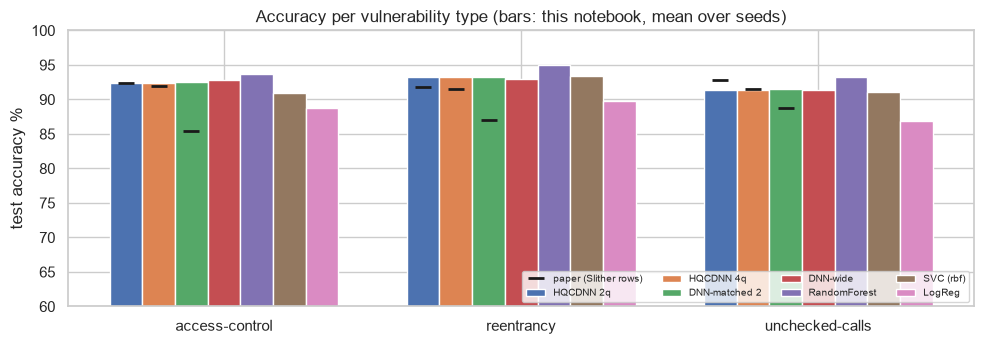

In [13]:
# Figure: test accuracy per task and model; the paper's Slither values are drawn as black markers
PAPER = {  # Tables 4, 5, 10: Slither rows, (accuracy, precision, recall, F1) in %, order: 2 qubit, 4 qubit, DNN
    "access-control":  {"2q": (92.4, 90.3, 94.9, 92.6), "4q": (92.0, 92.8, 91.2, 92.0), "dnn": (85.4, 84.0, 87.4, 85.7)},
    "reentrancy":      {"2q": (91.8, 91.2, 97.8, 94.4), "4q": (91.5, 87.8, 95.6, 91.5), "dnn": (87.0, 84.5, 89.5, 86.9)},
    "unchecked-calls": {"2q": (92.8, 92.5, 98.6, 95.4), "4q": (91.5, 89.8, 92.9, 91.4), "dnn": (88.7, 86.7, 90.4, 88.5)},
}
PAPER_NOT_CHECKABLE = {  # Tables 7 and 9: Slither rows without a counterpart in the substitute data
    "time manipulation (Table 7)": {"2q": (90.8, 91.9, 90.3, 91.1), "4q": (91.0, 90.5, 92.5, 91.5), "dnn": (87.8, 89.1, 87.3, 88.2)},
    "denial of service (Table 9)": {"2q": (93.0, 94.6, 91.7, 93.2), "4q": (93.7, 96.0, 91.7, 93.8), "dnn": (88.3, 89.0, 88.6, 88.8)},
}
fig, ax = plt.subplots(figsize=(10, 3.6)); w = 0.11
models = ["HQCDNN 2q", "HQCDNN 4q", "DNN-matched 2", "DNN-wide", "RandomForest", "SVC (rbf)", "LogReg"]
for j, m in enumerate(models):
    vals = [R[(R.task == t) & (R.model == m)].acc.mean() for t in TASKS]
    ax.bar(np.arange(len(TASKS)) + (j - 3) * w, vals, w, label=m)
for i, t in enumerate(TASKS):
    for key, off in [("2q", -3), ("4q", -2), ("dnn", -1)]:
        ax.plot(i + off * w, PAPER[t][key][0], "k_", markersize=12, mew=2)
ax.plot([], [], "k_", markersize=12, mew=2, label="paper (Slither rows)")
ax.set_xticks(range(len(TASKS))); ax.set_xticklabels(TASKS); ax.set_ylim(60, 100); ax.set_ylabel("test accuracy %")
ax.set_title("Accuracy per vulnerability type (bars: this notebook, mean over seeds)"); ax.legend(ncol=4, fontsize=7, loc="lower right")
plt.tight_layout(); plt.show()

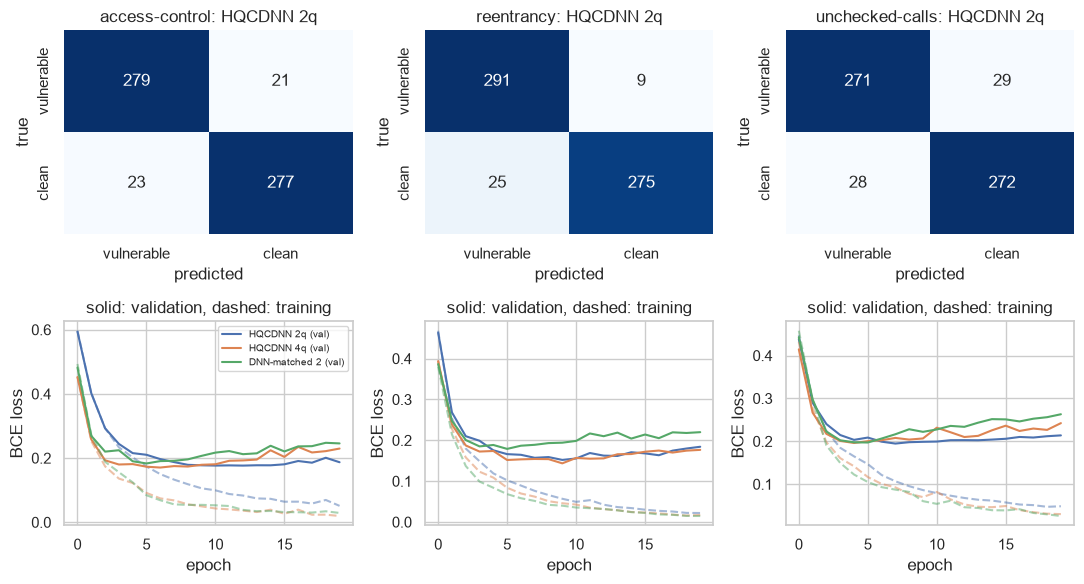

In [14]:
# Figure: confusion matrices (attack = vulnerable = positive class) and learning curves, first seed
fig, axes = plt.subplots(2, len(TASKS), figsize=(11, 6))
for i, t in enumerate(TASKS):
    k = keep[(t, "HQCDNN 2q")]
    cm = confusion_matrix(k["y"], k["pred"], labels=[1, 0])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[0, i], xticklabels=["vulnerable", "clean"], yticklabels=["vulnerable", "clean"])
    axes[0, i].set_title(f"{t}: HQCDNN 2q"); axes[0, i].set_xlabel("predicted"); axes[0, i].set_ylabel("true")
    for name, c in [("HQCDNN 2q", "C0"), ("HQCDNN 4q", "C1"), ("DNN-matched 2", "C2")]:
        h = np.array(keep[(t, name)]["hist"])
        axes[1, i].plot(h[:, 1], c, label=name + " (val)"); axes[1, i].plot(h[:, 0], c + "--", alpha=0.5)
    axes[1, i].set_xlabel("epoch"); axes[1, i].set_ylabel("BCE loss"); axes[1, i].set_title("solid: validation, dashed: training")
axes[1, 0].legend(fontsize=7)
plt.tight_layout(); plt.show()

## 8. Side claim: is the 4-qubit model 2-3 times slower?

The paper says training and inference of the 4-qubit model took "approximately 2 to 3 times longer" than the 2-qubit one. We have the wall-clock training times of both models (same data, same epochs, same CPU):

In [15]:
tm = R[R.model.isin(["HQCDNN 2q", "HQCDNN 4q", "DNN-matched 2"])].groupby(["task", "model"]).train_s.mean().unstack()
tm["4q / 2q"] = tm["HQCDNN 4q"] / tm["HQCDNN 2q"]
tm["HQCDNN 2q / DNN-matched"] = tm["HQCDNN 2q"] / tm["DNN-matched 2"]
display(tm.round(2))
RATIO = float(tm["4q / 2q"].mean())
print(f"mean training-time ratio 4 qubits / 2 qubits: {RATIO:.2f}  (paper: about 2-3)")
print(f"quantum layer vs matched classical layer: HQCDNN 2q is {tm['HQCDNN 2q / DNN-matched'].mean():.0f}x slower than its classical twin (simulation cost)")

model,DNN-matched 2,HQCDNN 2q,HQCDNN 4q,4q / 2q,HQCDNN 2q / DNN-matched
task,,,,,
access-control,9.19,29.67,47.65,1.61,3.23
reentrancy,9.65,26.81,45.34,1.69,2.78
unchecked-calls,7.90,25.48,40.11,1.57,3.22


mean training-time ratio 4 qubits / 2 qubits: 1.62  (paper: about 2-3)
quantum layer vs matched classical layer: HQCDNN 2q is 3x slower than its classical twin (simulation cost)


## 9. Side claim: bigrams beat unigrams

Section 3.2 of the paper says 1-gram TF-IDF gave low metrics and 2-grams were needed. We rerun the 2-qubit HQCDNN and the Random Forest with `ngram_range=(1, 1)` and `(2, 2)` on the same split (fitted on the training part only).

In [16]:
abl = []
for ng in [(1, 1), (2, 2)]:
    for seed in SEEDS:
        Xa_, Xb_, ya_, yb_, v_ = make_split(ABLATION_TASK, seed, ngram=ng)
        r = train_eval("hqcdnn", 2, Xa_, ya_, Xb_, yb_, seed)
        rf = RandomForestClassifier(n_estimators=300, random_state=seed, n_jobs=2).fit(Xa_, ya_)
        abl.append(dict(ngram=str(ng), seed=seed, features=Xa_.shape[1], hqcdnn_2q_acc=r["acc"], hqcdnn_2q_f1=r["f1"],
                        rf_acc=accuracy_score(yb_, rf.predict(Xb_)) * 100))
A = pd.DataFrame(abl)
A_tab = A.groupby("ngram").agg(features=("features", "mean"), hqcdnn_2q_acc=("hqcdnn_2q_acc", "mean"), hqcdnn_2q_f1=("hqcdnn_2q_f1", "mean"), rf_acc=("rf_acc", "mean")).round(1)
display(A_tab)
GAIN_BIGRAM = float(A_tab.loc["(2, 2)", "hqcdnn_2q_acc"] - A_tab.loc["(1, 1)", "hqcdnn_2q_acc"])
print(f"HQCDNN 2q accuracy gain of bigrams over unigrams on {ABLATION_TASK}: {GAIN_BIGRAM:+.1f} points")

,features,hqcdnn_2q_acc,hqcdnn_2q_f1,rf_acc
ngram,,,,
"(1, 1)",143.0,89.9,90.0,94.8
"(2, 2)",6584.7,93.3,93.3,95.0


HQCDNN 2q accuracy gain of bigrams over unigrams on reentrancy: +3.4 points


## 10. Side claim: the Wilcoxon test over 10-fold cross-validation

The paper trains the 2-qubit HQCDNN and a classical DNN with 10-fold CV (arithmetic task, Osiris + Oyente + Smartcheck) and reports a Wilcoxon signed-rank p-value of 0.0020 in favour of the hybrid. With only 10 folds the smallest possible two-sided p-value is exactly 2/1024 = 0.00195, i.e. **0.0020 means the hybrid won in all 10 folds**. We repeat the test on the reentrancy task (arithmetic is not available), with stratified folds, TF-IDF fitted inside each fold's training part, and DNN-matched as the classical competitor. Fewer folds and epochs are used in `FAST_MODE`.

In [17]:
vuln = pool[pool.cls.map(lambda c: CV_TASK in c)]; safe = pool[pool.cls.map(len) == 0]
n = min(N_PER_CLASS, len(vuln), len(safe))
d = pd.concat([vuln.sample(n, random_state=SEED), safe.sample(n, random_state=SEED)])
texts, ycv = np.array(d.ops.tolist(), dtype=object), np.r_[np.ones(n), np.zeros(n)].astype("float32")
cv_h, cv_d = [], []
t0 = time.time()
for f, (tr, te) in enumerate(StratifiedKFold(CV_FOLDS, shuffle=True, random_state=SEED).split(texts, ycv)):
    v_ = TfidfVectorizer(ngram_range=(2, 2), token_pattern=r"\S+", lowercase=False)
    Xa_ = v_.fit_transform(texts[tr]).astype("float32").toarray(); Xb_ = v_.transform(texts[te]).astype("float32").toarray()
    cv_h.append(train_eval("hqcdnn", 2, Xa_, ycv[tr], Xb_, ycv[te], SEED + f, epochs=CV_EPOCHS)["acc"])
    cv_d.append(train_eval("dnn_matched", 2, Xa_, ycv[tr], Xb_, ycv[te], SEED + f, epochs=CV_EPOCHS)["acc"])
    print(f"fold {f+1}/{CV_FOLDS}: HQCDNN 2q {cv_h[-1]:.1f} | DNN-matched {cv_d[-1]:.1f} | {time.time()-t0:.0f} s")
cv_h, cv_d = np.array(cv_h), np.array(cv_d)
stat = wilcoxon(cv_h, cv_d)
P_WILCOXON = float(stat.pvalue)
print(f"mean accuracy: HQCDNN 2q {cv_h.mean():.1f} +/- {cv_h.std():.1f} | DNN-matched {cv_d.mean():.1f} +/- {cv_d.std():.1f}")
print(f"Wilcoxon signed-rank p = {P_WILCOXON:.4f}; hybrid better in {(cv_h > cv_d).sum()} of {CV_FOLDS} folds (paper: p = 0.0020)")

fold 1/10: HQCDNN 2q 95.0 | DNN-matched 95.0 | 38 s


fold 2/10: HQCDNN 2q 93.0 | DNN-matched 92.3 | 79 s


fold 3/10: HQCDNN 2q 94.7 | DNN-matched 95.0 | 120 s


fold 4/10: HQCDNN 2q 95.0 | DNN-matched 94.7 | 164 s


fold 5/10: HQCDNN 2q 94.7 | DNN-matched 94.0 | 214 s


fold 6/10: HQCDNN 2q 92.7 | DNN-matched 91.3 | 264 s


fold 7/10: HQCDNN 2q 93.3 | DNN-matched 93.7 | 303 s


fold 8/10: HQCDNN 2q 93.0 | DNN-matched 92.3 | 343 s


fold 9/10: HQCDNN 2q 95.7 | DNN-matched 95.7 | 380 s


fold 10/10: HQCDNN 2q 95.7 | DNN-matched 94.0 | 420 s
mean accuracy: HQCDNN 2q 94.3 +/- 1.1 | DNN-matched 93.8 +/- 1.3
Wilcoxon signed-rank p = 0.0547; hybrid better in 6 of 10 folds (paper: p = 0.0020)


## 11. Side by side with the paper, claim by claim

Verdict rule (fixed in advance): a number is **reproduced** if it is within 2 accuracy points (or 0.02 in F1, i.e. 2 points) of the paper, **exceeded** / **not reached** otherwise (with the gap), and **cannot be checked** when the substitute data has no counterpart or the claim is not testable here. Remember that the data differ (deployed bytecode instead of compiled source, Slither labels only, other contracts), so even "reproduced" means "same magnitude on the same kind of task", not confirmation of the paper's own experiment.

In [18]:
def verdict(paper, mine, tol=2.0):
    d = mine - paper
    if abs(d) <= tol: return "reproduced"
    return f"exceeded (+{d:.1f})" if d > 0 else f"not reached ({d:.1f})"

def mean_of(task, model, col): return float(R[(R.task == task) & (R.model == model)][col].mean())
mapping = {"2q": "HQCDNN 2q", "4q": "HQCDNN 4q", "dnn": "DNN-matched 2"}
rows = []
tbl = {"access-control": "Table 4", "reentrancy": "Table 5", "unchecked-calls": "Table 10"}
for t in TASKS:
    for key, label in [("2q", "2 qubits"), ("4q", "4 qubits"), ("dnn", "DNN")]:
        for mi, mname in [(0, "accuracy"), (3, "F1")]:
            p = PAPER[t][key][mi]; m = mean_of(t, mapping[key], "acc" if mi == 0 else "f1")
            rows.append((f"{tbl[t]} Slither/{t}, {label}: {mname} (mine: " + ("HQCDNN" if key != "dnn" else "DNN-matched") + ")", f"{p:.1f}", f"{m:.1f}", verdict(p, m)))
for nm, v in PAPER_NOT_CHECKABLE.items():
    rows.append((f"{nm}, Slither row (all models)", f"2q {v['2q'][0]} / 4q {v['4q'][0]} / DNN {v['dnn'][0]}", "-", "cannot be checked (no such detector in the public data)"))
rows.append(("Abstract: accuracy range 78.2-96.4 % over all (tool, vulnerability) rows", "78.2-96.4", f"{R[R.model.isin(['HQCDNN 2q','HQCDNN 4q'])].groupby(['task','model']).acc.mean().min():.1f}-{R[R.model.isin(['HQCDNN 2q','HQCDNN 4q'])].groupby(['task','model']).acc.mean().max():.1f}", "cannot be checked (only 3 of 7 types, Slither only); see the per-row verdicts above"))

# qualitative claims
for t in TASKS:
    a2, ad = mean_of(t, "HQCDNN 2q", "acc"), mean_of(t, "DNN-matched 2", "acc")
    aw = mean_of(t, "DNN-wide", "acc")
    rows.append((f"Claim: 2-qubit HQCDNN beats the DNN on {t} (paper gap +{PAPER[t]['2q'][0]-PAPER[t]['dnn'][0]:.1f})", f"+{PAPER[t]['2q'][0]-PAPER[t]['dnn'][0]:.1f}",
                 f"{a2-ad:+.1f} vs DNN-matched, {a2-aw:+.1f} vs DNN-wide",
                 "reproduced" if (a2 - ad) >= 2.0 else f"not reached (gap {a2-ad:+.1f} vs DNN-matched, needs >= +2)"))
best_rf = {t: mean_of(t, "RandomForest", "acc") for t in TASKS}
for t in TASKS:
    a2 = mean_of(t, "HQCDNN 2q", "acc")
    rows.append((f"Extra check (not in the paper): HQCDNN 2q vs Random Forest on {t}", "-", f"HQCDNN {a2:.1f} vs RF {best_rf[t]:.1f}",
                 "RF at least as good" if best_rf[t] >= a2 - 0.5 else "HQCDNN better"))
d42 = np.mean([mean_of(t, "HQCDNN 4q", "acc") - mean_of(t, "HQCDNN 2q", "acc") for t in TASKS])
rows.append(("Claim: 4 qubits give only slightly different accuracy than 2 qubits (|gap| small)", "-0.3 to -1.3 on the three Slither rows", f"{d42:+.1f} (mean over tasks)",
             "reproduced" if abs(d42) <= 2.0 else f"not reached (gap {d42:+.1f})"))
rows.append(("Claim: 4-qubit training takes about 2-3x longer than 2-qubit", "2-3x", f"{RATIO:.2f}x",
             "reproduced" if 1.8 <= RATIO <= 3.4 else ("exceeded (slower than 3x)" if RATIO > 3.4 else "not reached (less than 2x)")))
rows.append(("Claim: bigrams (2-gram) beat unigrams", "bigram better (no number)", f"{GAIN_BIGRAM:+.1f} points ({ABLATION_TASK}, HQCDNN 2q)",
             "reproduced" if GAIN_BIGRAM > 0 else "not reached (unigrams are as good or better here)"))
rows.append((f"Claim: Wilcoxon over {CV_FOLDS}-fold CV, HQCDNN 2q vs DNN: p = 0.0020 (arithmetic task)", "0.0020", f"{P_WILCOXON:.4f} ({CV_TASK}; hybrid better in {(cv_h > cv_d).sum()}/{CV_FOLDS} folds)",
             "reproduced" if (P_WILCOXON <= 0.05 and cv_h.mean() > cv_d.mean()) else ("not reached (no significant advantage of the hybrid" + ("; with only %d folds p cannot go below %.4f" % (CV_FOLDS, 2 / 2 ** CV_FOLDS) if 2 / 2 ** CV_FOLDS > 0.05 else "") + ")")))
rows.append(("Claim: hybrid is a feasible route to quantum advantage / hardware benefit", "implied", "-", "cannot be checked (simulator only, no hardware, no runtime advantage; see section 8)"))
comp = pd.DataFrame(rows, columns=["Claim", "Paper", "This notebook", "Verdict"])
pd.set_option("display.max_colwidth", 120, "display.width", 250)
display(comp.style.hide(axis="index").set_properties(**{"text-align": "left"}))
print(comp.Verdict.map(lambda v: v.split(" (")[0]).value_counts().to_string())
print(f"\nTotal notebook runtime: {(time.time()-T_NOTEBOOK)/60:.1f} min (FAST_MODE={FAST_MODE})")

Claim,Paper,This notebook,Verdict
"Table 4 Slither/access-control, 2 qubits: accuracy (mine: HQCDNN)",92.4,92.4,reproduced
"Table 4 Slither/access-control, 2 qubits: F1 (mine: HQCDNN)",92.6,92.4,reproduced
"Table 4 Slither/access-control, 4 qubits: accuracy (mine: HQCDNN)",92.0,92.4,reproduced
"Table 4 Slither/access-control, 4 qubits: F1 (mine: HQCDNN)",92.0,92.4,reproduced
"Table 4 Slither/access-control, DNN: accuracy (mine: DNN-matched)",85.4,92.5,exceeded (+7.1)
"Table 4 Slither/access-control, DNN: F1 (mine: DNN-matched)",85.7,92.6,exceeded (+6.9)
"Table 5 Slither/reentrancy, 2 qubits: accuracy (mine: HQCDNN)",91.8,93.3,reproduced
"Table 5 Slither/reentrancy, 2 qubits: F1 (mine: HQCDNN)",94.4,93.3,reproduced
"Table 5 Slither/reentrancy, 4 qubits: accuracy (mine: HQCDNN)",91.5,93.3,reproduced
"Table 5 Slither/reentrancy, 4 qubits: F1 (mine: HQCDNN)",91.5,93.3,reproduced


Verdict
reproduced             13
exceeded                6
not reached             6
cannot be checked       4
RF at least as good     3

Total notebook runtime: 39.8 min (FAST_MODE=False)


## 12. Reading the paper critically

- **What is compared is under-specified.** The paper does not describe its classical DNN (width, depth, epochs, optimiser), the learning rate, the number of epochs or the batch size. The headline "quantum beats DNN" depends entirely on that unnamed baseline. In this notebook the gap between the HQCDNN and its matched classical twin is the fair comparison: same dense reduction, same width, and a tanh in place of the quantum node. A wide DNN and a Random Forest on the same TF-IDF matrix are the sanity check the paper lacks.
- **Two qubits cannot hold two thousand features.** The first dense layer does all the work; the quantum node sees only 2 (or 4) numbers and returns 2 (or 4) numbers in [-1, 1], a smooth bounded function with a handful of parameters. A two-qubit circuit with one CNOT is something a small classical layer can imitate (that is exactly what DNN-matched does). Any gain of the quantum node over a matched classical layer is therefore small and hard to separate from seed noise, and a fair test needs repeated seeds, as in section 10.
- **Labels come from the same tools the model imitates.** The model learns to reproduce what Slither, Mythril, Oyente, ... flag, not what is truly exploitable. A contract that Slither misses is "non-vulnerable" in training. Such a model is useful only if it is faster than the tools or if it generalises where they fail; the paper shows neither. The very high scores (92-96 %) also reflect how deterministic the static-analysis rules are.
- **Opcode n-grams on the compiled contract leak library structure.** Two contracts that share a library or compiler version share most bigrams. We remove byte-identical clones; near-clones remain, and the paper does not say whether it removed any.
- **Reporting.** No seeds, no confidence intervals (except one Wilcoxon test on one cell), no test of the 7 tool/vulnerability rows against a strong classical model such as a gradient-boosted tree or a Random Forest. The 78.2 % low end (Mythril, arithmetic) is described as a limit of the tool, not of the model, without evidence. The "96.4 %" top value is, to our reading, Osiris+Oyente+Smartcheck arithmetic (Table 6); the combined tool rows have far fewer vulnerable contracts than 3 665, so the classes are balanced by shrinking the clean class.
- **No quantum advantage claim is testable.** The model is run on a classical simulator; a 2-qubit circuit is trivially simulated, and the quantum part is about as expensive as the classical rest (section 8 shows the simulation overhead per sample). Whether any of this would help on hardware is untested (the authors say so).
- **The p = 0.0020 is the smallest p-value 10 folds can give.** It says the hybrid won every fold in the paper's setting, which is a statement about one cell and one baseline, not about HQCDNNs in general.

## 13. Exercises

1. **Seeds and size.** Run with `FAST_MODE = False` and print mean +/- std for all models. For which task is the HQCDNN-vs-DNN-matched gap larger than the standard deviation?
2. **Depth of the quantum layer.** Set `N_ENTANGLER_LAYERS = 3` and `QUBITS = [2, 4, 6]`. Does accuracy rise with more trainable circuit parameters? How does the training time grow (section 8)?
3. **Operands.** Keep the operands of `PUSH` in `opcode_text` (for instance `PUSH4 0xa9059cbb`) so that function selectors become words. Which bigrams become the most typical for the reentrancy class, and does a Random Forest improve?
4. **Other encodings.** Replace `AngleEmbedding(rotation="X")` by `rotation="Y"` or add `qml.templates.StronglyEntanglingLayers`. Does anything change relative to seed noise?
5. **More labels.** Use the dataset's `arithmetic` (divide-before-multiply) or `locked-ether` classes, or the SmartBugs Wild labels of Mythril, Oyente and Osiris (see the SmartBugs-wild and `smartbugs-results` repositories), to try the paper's other rows, and compare the dataset-wide range with the paper's 78.2-96.4 %.